In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import (
    RandomizedSearchCV, train_test_split
)
from sklearn.metrics import (
    make_scorer, accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.base import clone

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from scipy.stats import randint

import time
import warnings
warnings.filterwarnings("ignore")



In [92]:
# Set seed for reproducibility
seed = 67
rng = np.random.default_rng(seed) 

# Show all dataframe columns
pd.set_option("display.max_columns", None)

# Seaborn plot colors
sns.set_palette("viridis")

# EDA and Data Preparation

In [93]:
hea_df = pd.read_csv("dataset10387_70.csv", index_col=0)

# Include Inv Omega parameter
hea_df['Inv Omega'] = hea_df['Enthalpy'].abs() / hea_df['Melting_point_K'] * hea_df['entropy']

# Drop Geo parameter
hea_df = hea_df.drop('Geo', axis=1)

hea_df.shape

(10387, 70)

In [94]:
hea_df.head()

,index,Num_el,Li,Be,B,C,N,Na,Mg,Al,Si,P,Ca,Sc,Ti,V,Cr,Mn,Fe,Co,Ni,Cu,Zn,Ga,Ge,Sr,Y,Zr,Nb,Mo,Ru,Rh,Pd,Ag,Cd,In,Sn,Sb,La,Ce,Pr,Nd,Sm,Gd,Tb,Dy,Ho,Er,Tm,Yb,Hf,Ta,W,Re,Ir,VEC,Pauling_EN,Melting_point_K,DFT_LDA_Etot,outer_shell_electrons,no_of_valence_electrons,Atomic_radius_calculated,Atomic_weight,Pauling_EN_div,entropy,Atomic_radius_calculated_dif,Enthalpy,Phase,E_per_el,Inv Omega
0,AlAuCoCrCuNi,6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.166667,0.0,0.0,0.0,0.0,0.000000,0.000000,0.166667,0.000000,0.000000,0.166667,0.166667,0.166667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.666667,1.916667,1541.816667,-3944.599012,1.666667,10.666667,1.506667,76.186167,0.302802,14.896688,11.759011,-10.000000,FCC+IM,-657.433169,0.096618
1,AlCoCrCu0.5Fe,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.222222,0.0,0.0,0.0,0.0,0.000000,0.000000,0.222222,0.000000,0.222222,0.222222,0.000000,0.111111,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.000000,1.762222,1626.150000,-1054.094014,1.888889,7.000000,1.476667,50.118000,0.116978,13.145213,11.545564,-8.197531,FCC+IM,-210.818803,0.066266
2,AlCoCrCuFe,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.200000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.200000,0.000000,0.200000,0.200000,0.000000,0.200000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.400000,1.776000,1599.150000,-1112.463198,1.800000,7.400000,1.474000,51.460800,0.118423,13.380867,10.986313,-5.920000,FCC+IM,-222.492640,0.049536
3,AlCoCrCuFeMnNi,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.142857,0.0,0.0,0.0,0.0,0.000000,0.000000,0.142857,0.142857,0.142857,0.142857,0.142857,0.142857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.714286,1.762857,1605.578571,-1173.763652,1.857143,7.714286,1.495714,52.990714,0.140378,16.178297,9.674466,-6.367347,FCC+IM,-167.680522,0.064159
4,Al0.125CoCrCuFeMnNiTiV,9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.015385,0.0,0.0,0.0,0.0,0.123077,0.123077,0.123077,0.123077,0.123077,0.123077,0.123077,0.123077,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.430769,1.735538,1786.934615,-1182.910883,1.769231,7.430769,1.588615,54.908892,0.148324,17.683355,7.155794,-9.520473,BCC+FCC,-131.434543,0.094214


In [95]:
hea_df.describe()

,Num_el,Li,Be,B,C,N,Na,Mg,Al,Si,P,Ca,Sc,Ti,V,Cr,Mn,Fe,Co,Ni,Cu,Zn,Ga,Ge,Sr,Y,Zr,Nb,Mo,Ru,Rh,Pd,Ag,Cd,In,Sn,Sb,La,Ce,Pr,Nd,Sm,Gd,Tb,Dy,Ho,Er,Tm,Yb,Hf,Ta,W,Re,Ir,VEC,Pauling_EN,Melting_point_K,DFT_LDA_Etot,outer_shell_electrons,no_of_valence_electrons,Atomic_radius_calculated,Atomic_weight,Pauling_EN_div,entropy,Atomic_radius_calculated_dif,Enthalpy,E_per_el,Inv Omega
count,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000,10387.000000
mean,5.070569,0.000883,0.002339,0.002796,0.001346,0.000135,0.000071,0.007152,0.111668,0.003153,0.000111,0.001147,0.000058,0.042590,0.019056,0.127179,0.044024,0.137885,0.124189,0.158056,0.103412,0.002260,0.000146,0.000225,0.000836,0.001420,0.026882,0.024833,0.016832,0.000218,0.000016,0.001778,0.001042,0.000472,0.000505,0.001386,0.000454,0.002334,0.002067,0.000268,0.001692,0.000118,0.001140,0.000162,0.000352,0.000159,0.000257,0.000019,0.000284,0.007911,0.010844,0.003775,0.000206,0.000016,7.232385,1.751811,1745.905779,-1767.982014,1.868847,7.631748,1.556127,59.492249,0.144618,12.469586,9.380058,-8.275954,-376.310947,0.067604
std,0.878377,0.016369,0.027535,0.028125,0.017662,0.003103,0.004678,0.059143,0.139951,0.026073,0.004640,0.018619,0.003399,0.094919,0.061429,0.113331,0.094315,0.121130,0.109183,0.126180,0.118794,0.027653,0.009135,0.007031,0.015118,0.017166,0.081676,0.070298,0.056648,0.009078,0.001635,0.031000,0.022683,0.015708,0.013718,0.022520,0.012996,0.036111,0.033759,0.012074,0.029322,0.005711,0.022142,0.006997,0.012445,0.006849,0.009785,0.001962,0.007505,0.038407,0.045675,0.028993,0.008066,0.001635,1.478304,0.113765,317.926412,1547.110909,0.366867,1.544124,0.142582,16.913719,0.064304,2.026149,4.845531,9.779897,448.560675,0.059582
min,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.300000,1.165700,437.533333,-19690.419540,1.000000,1.615385,0.893846,12.054923,0.000000,1.650456,0.000000,-122.062500,-9845.209770,0.000000
25%,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.571429,1.729649,1611.272016,-1406.332084,1.716717,7.000000,1.477979,51.952074,0.113017,11.936420,5.636285,-12.507189,-292.288952,0.023122
50%,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.076864,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.142857,0.000000,0.152038,0.137000,0.166667,0.083333,0.000000,0.000000,0.000000,0.0000

In [96]:
hea_df.columns

Index(['index', 'Num_el', 'Li', 'Be', 'B', 'C', 'N', 'Na', 'Mg', 'Al', 'Si',
       'P', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn',
       'Ga', 'Ge', 'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd',
       'In', 'Sn', 'Sb', 'La', 'Ce', 'Pr', 'Nd', 'Sm', 'Gd', 'Tb', 'Dy', 'Ho',
       'Er', 'Tm', 'Yb', 'Hf', 'Ta', 'W', 'Re', 'Ir', 'VEC', 'Pauling_EN',
       'Melting_point_K', 'DFT_LDA_Etot', 'outer_shell_electrons',
       'no_of_valence_electrons', 'Atomic_radius_calculated', 'Atomic_weight',
       'Pauling_EN_div', 'entropy', 'Atomic_radius_calculated_dif', 'Enthalpy',
       'Phase', 'E_per_el', 'Inv Omega'],
      dtype='str')

In [97]:
# Rename columns for clarity
renamed_cols = {
    'index': 'Alloy',
    'Num_el': 'Element Count',
    'Pauling_EN': 'Avg Electronegativity',
    'Melting_point_K': 'Melting Temp',
    'DFT_LDA_Etot': 'DFT Energy',
    'outer_shell_electrons': 'Outer Shell Electrons',
    'no_of_valence_electrons': 'Valence Electrons',
    'Atomic_radius_calculated': 'Atomic Radius',
    'Atomic_weight': 'Atomic Weight',
    'Pauling_EN_div': 'Electronegativity Diff',
    'entropy': 'Mixing Entropy',
    'Atomic_radius_calculated_dif': 'Atom Size Diff',
    'Enthalpy': 'Mixing Enthalpy',
    'Phase': 'Phase',
    'E_per_el': 'Energy per Element',
}

hea_df = hea_df.rename(columns=renamed_cols)
hea_df.head()

,Alloy,Element Count,Li,Be,B,C,N,Na,Mg,Al,Si,P,Ca,Sc,Ti,V,Cr,Mn,Fe,Co,Ni,Cu,Zn,Ga,Ge,Sr,Y,Zr,Nb,Mo,Ru,Rh,Pd,Ag,Cd,In,Sn,Sb,La,Ce,Pr,Nd,Sm,Gd,Tb,Dy,Ho,Er,Tm,Yb,Hf,Ta,W,Re,Ir,VEC,Avg Electronegativity,Melting Temp,DFT Energy,Outer Shell Electrons,Valence Electrons,Atomic Radius,Atomic Weight,Electronegativity Diff,Mixing Entropy,Atom Size Diff,Mixing Enthalpy,Phase,Energy per Element,Inv Omega
0,AlAuCoCrCuNi,6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.166667,0.0,0.0,0.0,0.0,0.000000,0.000000,0.166667,0.000000,0.000000,0.166667,0.166667,0.166667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.666667,1.916667,1541.816667,-3944.599012,1.666667,10.666667,1.506667,76.186167,0.302802,14.896688,11.759011,-10.000000,FCC+IM,-657.433169,0.096618
1,AlCoCrCu0.5Fe,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.222222,0.0,0.0,0.0,0.0,0.000000,0.000000,0.222222,0.000000,0.222222,0.222222,0.000000,0.111111,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.000000,1.762222,1626.150000,-1054.094014,1.888889,7.000000,1.476667,50.118000,0.116978,13.145213,11.545564,-8.197531,FCC+IM,-210.818803,0.066266
2,AlCoCrCuFe,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.200000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.200000,0.000000,0.200000,0.200000,0.000000,0.200000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.400000,1.776000,1599.150000,-1112.463198,1.800000,7.400000,1.474000,51.460800,0.118423,13.380867,10.986313,-5.920000,FCC+IM,-222.492640,0.049536
3,AlCoCrCuFeMnNi,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.142857,0.0,0.0,0.0,0.0,0.000000,0.000000,0.142857,0.142857,0.142857,0.142857,0.142857,0.142857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.714286,1.762857,1605.578571,-1173.763652,1.857143,7.714286,1.495714,52.990714,0.140378,16.178297,9.674466,-6.367347,FCC+IM,-167.680522,0.064159
4,Al0.125CoCrCuFeMnNiTiV,9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.015385,0.0,0.0,0.0,0.0,0.123077,0.123077,0.123077,0.123077,0.123077,0.123077,0.123077,0.123077,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.430769,1.735538,1786.934615,-1182.910883,1.769231,7.430769,1.588615,54.908892,0.148324,17.683355,7.155794,-9.520473,BCC+FCC,-131.434543,0.094214


## Remove duplicates and inconsistensies

In [98]:
# Remove alloy duplicates
deduped = hea_df.drop_duplicates()

# Drop alloys with inconsistent phases
inconsistent = deduped['Alloy'].value_counts()
inconsistent = deduped['Alloy'].isin(inconsistent[inconsistent > 1].index)
hea_df = deduped[~inconsistent].sort_index()

# Remove rows with NaN and inf values
hea_df = hea_df.replace([np.inf, -np.inf], np.nan).dropna()

hea_df.shape

(6676, 70)

## Phases Distribution

### Original Distribution

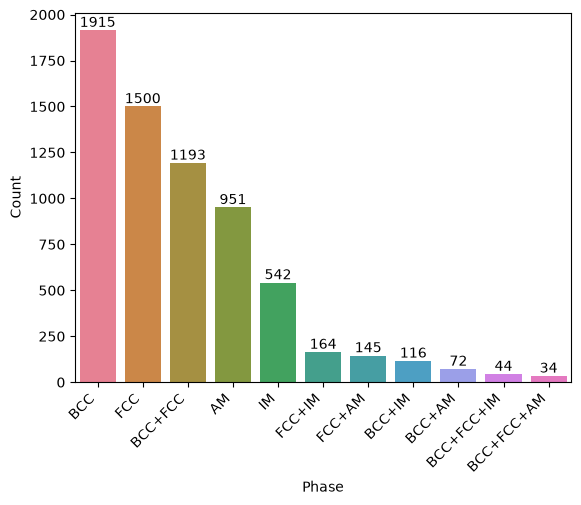

In [99]:
order = hea_df["Phase"].value_counts().index
ax = sns.countplot(data=hea_df, x="Phase", order=order, hue="Phase", hue_order=order)
for container in ax.containers: ax.bar_label(container)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Count")
plt.show()

### Convert 'Phase' into multi-label binary columns

In [ ]:
# Split the phase strings into lists
phase_lists = hea_df['Phase'].str.split('+')

phase_cols = ['BCC', 'FCC', 'IM', 'AM']
phase_combs = ['BCC', 'FCC', 'BCC+FCC', 'AM', 'IM', 'FCC+IM', 'FCC+AM',
               'BCC+IM', 'BCC+AM', 'BCC+FCC+IM', 'BCC+FCC+AM']
has_phase_cols = ['has_BCC', 'has_FCC', 'has_IM', 'has_AM']

mlb = MultiLabelBinarizer(classes=phase_cols)
encoded = mlb.fit_transform(phase_lists)
encoded_df = pd.DataFrame(encoded, columns=has_phase_cols, index=hea_df.index)

# Attach to original df
hea_df = pd.concat([hea_df, encoded_df], axis=1)

In [101]:
hea_df[['Alloy', 'Phase'] + has_phase_cols].head(10)

,Alloy,Phase,has_BCC,has_FCC,has_IM,has_AM
0,AlAuCoCrCuNi,FCC+IM,0,1,1,0
4,Al0.125CoCrCuFeMnNiTiV,BCC+FCC,1,1,0,0
5,Al0.25CoCrCuFeMnNiTiV,BCC,1,0,0,0
6,Al0.67CoCrCuFeMnNiTiV,BCC+IM,1,0,1,0
7,AlCoCrCuFeMo0.2Ni,BCC+FCC,1,1,0,0
8,Al0.25CoCrCu0.75FeNi,FCC,0,1,0,0
9,Al0.3CoCrCuFeNi,FCC,0,1,0,0
10,Al0.5CoCrCu0.5FeNi,FCC,0,1,0,0
12,Al0.5CoCrCuFeNi,FCC,0,1,0,0
19,AlCoCrCu0.25FeNi,BCC,1,0,0,0


### Multi-label Distribution

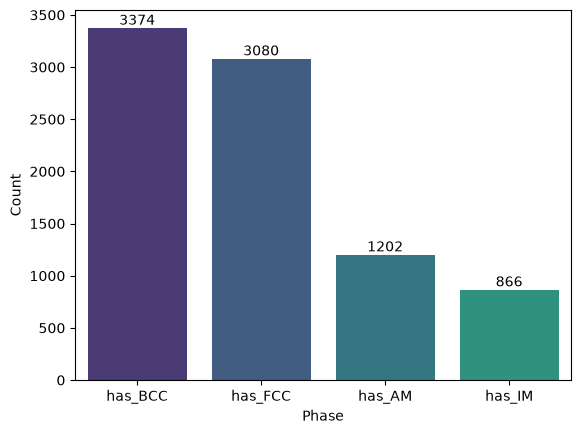

In [102]:
counts = hea_df[has_phase_cols].sum().sort_values(ascending=False)

ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index)
for container in ax.containers: ax.bar_label(container)

plt.ylabel('Count')
plt.xlabel('Phase')
plt.show()

## Alloying Elements Contribution

In [103]:
hea_df.iloc[:, 2:55].columns

Index(['Li', 'Be', 'B', 'C', 'N', 'Na', 'Mg', 'Al', 'Si', 'P', 'Ca', 'Sc',
       'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'Ge', 'Sr',
       'Y', 'Zr', 'Nb', 'Mo', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb',
       'La', 'Ce', 'Pr', 'Nd', 'Sm', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb',
       'Hf', 'Ta', 'W', 'Re', 'Ir'],
      dtype='str')

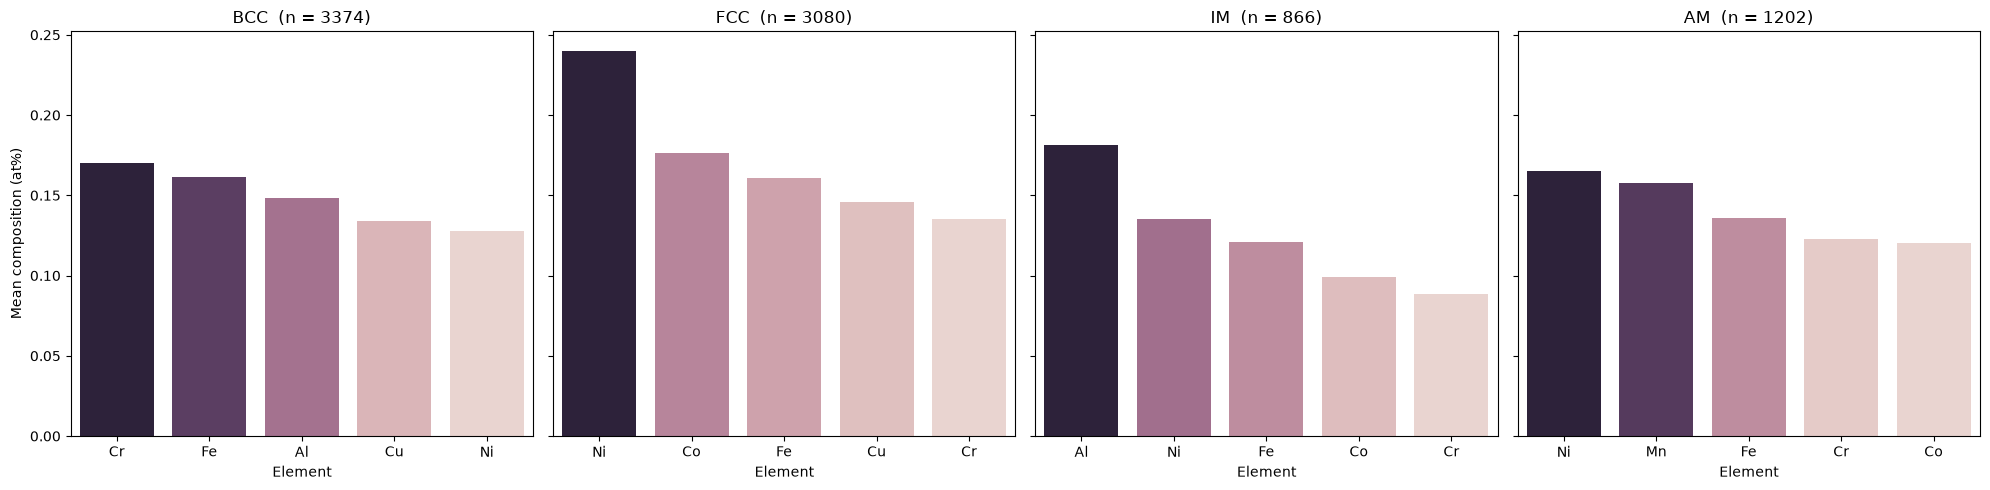

In [104]:
elem_cols = hea_df.iloc[:, 2:55].columns

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

for ax, phase, flag in zip(axes, phase_cols, has_phase_cols):
    # Per phase subset
    subset = hea_df.loc[hea_df[flag] == 1, elem_cols]

    # Get top 5 elements
    means = subset.mean().sort_values(ascending=False).head(5)

    sns.barplot(x=means.index, y=means.values, ax=ax, hue=means.values, legend=False)
    ax.set_title(f'{phase}  (n = {len(subset)})')
    ax.set_ylabel('Mean composition (at%)' if phase == 'BCC' else '')
    ax.set_xlabel('Element')

plt.tight_layout()
plt.show()

## Feature Correlation

In [105]:
# Set features, X
feature_cols = ['VEC', 'Avg Electronegativity', 'Melting Temp', 'Outer Shell Electrons', 
                'Valence Electrons', 'Atomic Radius', 'Atomic Weight', 'Electronegativity Diff', 
                'Mixing Entropy', 'Atom Size Diff', 'Mixing Enthalpy', 'Inv Omega']

X = hea_df[feature_cols]

### Correlation Heatmaps

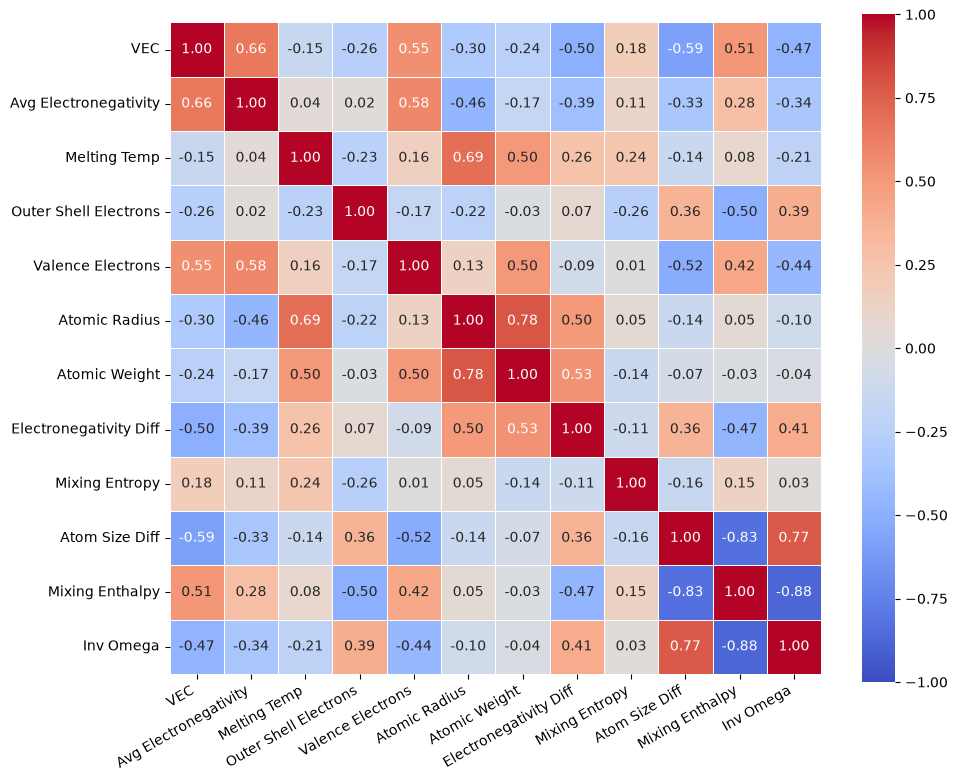

In [106]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, fmt='.2f',vmin=-1, vmax=1, square=True, linewidths=0.5, cmap='coolwarm')
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Box Plots

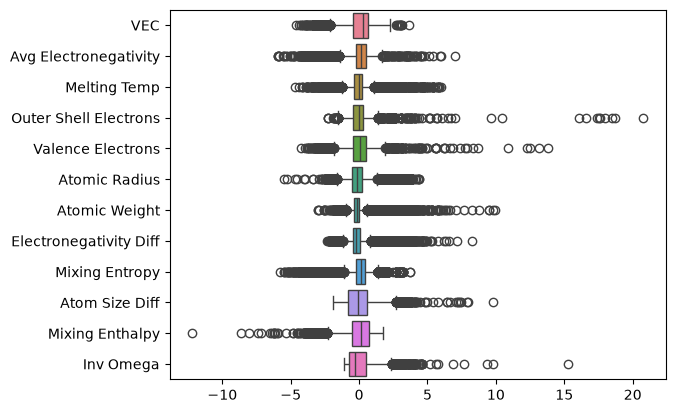

In [107]:
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)
sns.boxplot(data=X_scaled, orient="h")
plt.show()

## Feature Selection via ExtraTreesClassifier

In [108]:
# Set baseline and multilabel targets, y
y_base = hea_df["Phase"]
y_mulb = hea_df[has_phase_cols]

print("Features")
for i, col in enumerate(X.columns):
    print(f"{i}: {col}")

print("\nMulti-label Target")
for i, col in enumerate(y_mulb.columns):
    print(f"{i}: {col}")

Features
0: VEC
1: Avg Electronegativity
2: Melting Temp
3: Outer Shell Electrons
4: Valence Electrons
5: Atomic Radius
6: Atomic Weight
7: Electronegativity Diff
8: Mixing Entropy
9: Atom Size Diff
10: Mixing Enthalpy
11: Inv Omega

Multi-label Target
0: has_BCC
1: has_FCC
2: has_IM
3: has_AM


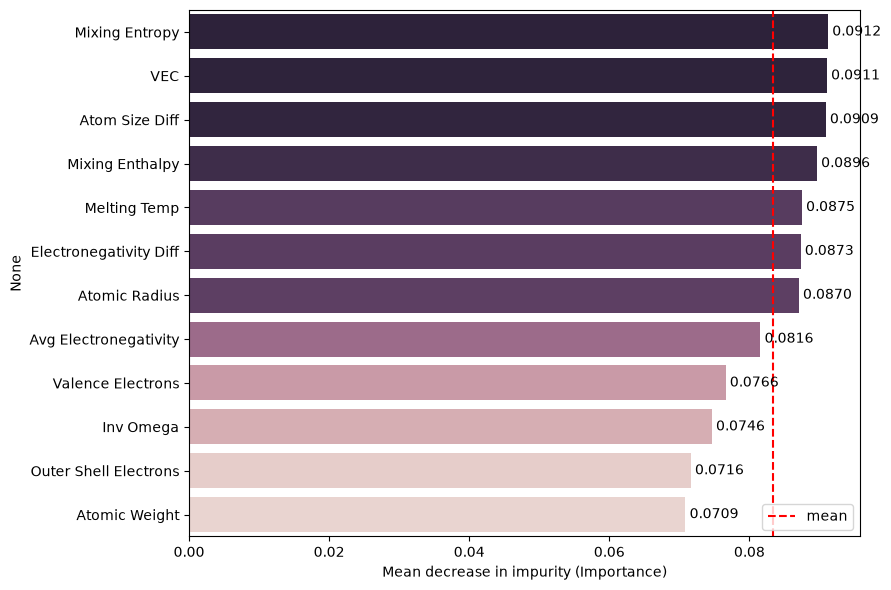

In [109]:
y_le = LabelEncoder().fit_transform(y_base)

# Fit Extra Trees
etc = ExtraTreesClassifier(
    n_estimators=500,
    max_features='sqrt',
    random_state=seed,
    n_jobs=-1,
    class_weight='balanced',
)

etc.fit(X, y_le)
importances = pd.Series(etc.feature_importances_, index=X.columns).sort_values(ascending=False)

# Plot importances
plt.figure(figsize=(9, 6))
ax = sns.barplot(x=importances.values, y=importances.index, hue=importances.values, legend=False)
ax.axvline(importances.mean(), color='r', ls='--', label='mean')
for container in ax.containers: ax.bar_label(container, fmt="%.4f", padding=3)
ax.set_xlabel('Mean decrease in impurity (Importance)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [110]:
# Select features
selector = SelectFromModel(etc, threshold='mean', prefit=True)
selected_features = X.columns[selector.get_support()].tolist()

print(f"Selected {len(selected_features)} of {len(X.columns)} features:")
print(selected_features)

X = X[selected_features]

Selected 7 of 12 features:
['VEC', 'Melting Temp', 'Atomic Radius', 'Electronegativity Diff', 'Mixing Entropy', 'Atom Size Diff', 'Mixing Enthalpy']


## Outlier Removal via Isolation Forest

In [111]:
def remove_outliers_per_class(X, y):
    X_arr = np.asarray(X)
    y_arr = np.asarray(y)

    y_mask = np.ones(len(y_arr), dtype=bool)

    for phase in np.unique(y_arr):
        idx = np.where(y_arr == phase)[0]
        X_phase = X_arr[idx]

        iso = IsolationForest(
            contamination="auto",
            random_state=seed,
            n_estimators=200,
            n_jobs=-1,
        )
        preds = iso.fit_predict(X_phase)
        outlier_idx = idx[preds == -1]
        y_mask[outlier_idx] = False
        n_out = len(outlier_idx)

        print(f"{phase:<10} | {len(idx)-n_out:<6} | {n_out:<7} | {100*n_out/len(idx):.1f}%")

    return y_mask

print("Class      | Inlier | Outlier | % Removed")
print("-"*42)

y_mask = remove_outliers_per_class(X, y_base)
X = X.iloc[y_mask].reset_index(drop=True)
y_base = y_base.loc[y_mask].reset_index(drop=True)
y_mulb = y_mulb.loc[y_mask].reset_index(drop=True)

Class      | Inlier | Outlier | % Removed
------------------------------------------
AM         | 715    | 236     | 24.8%
BCC        | 1560   | 355     | 18.5%
BCC+AM     | 57     | 15      | 20.8%
BCC+FCC    | 1061   | 132     | 11.1%
BCC+FCC+AM | 25     | 9       | 26.5%
BCC+FCC+IM | 31     | 13      | 29.5%
BCC+IM     | 90     | 26      | 22.4%
FCC        | 1380   | 120     | 8.0%
FCC+AM     | 115    | 30      | 20.7%
FCC+IM     | 139    | 25      | 15.2%
IM         | 449    | 93      | 17.2%


### After Outlier Removal

In [112]:
X.shape

(5622, 7)

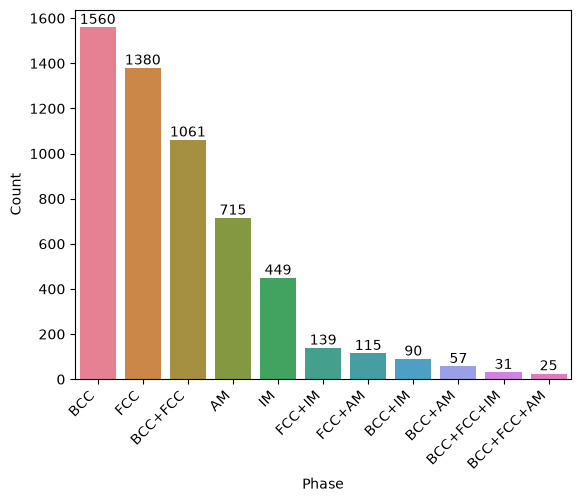

In [113]:
# Phase Distribution (Baseline)

order = y_base.value_counts().index
ax = sns.countplot(x=y_base, order=order, hue=y_base, hue_order=order, legend=False)
for container in ax.containers: ax.bar_label(container)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Count")
plt.show()

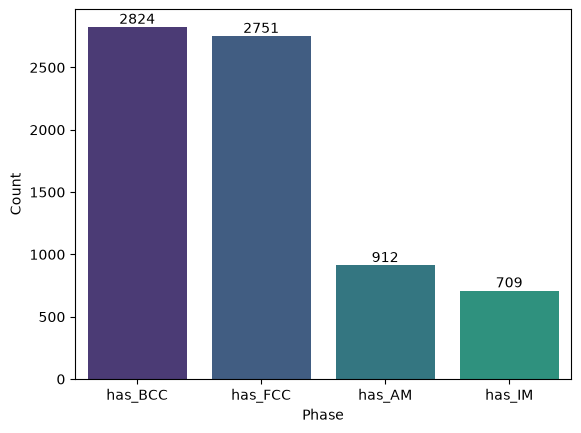

In [114]:
# Phase Distribution (Multilabel)

counts = y_mulb[has_phase_cols].sum().sort_values(ascending=False)
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index)
for container in ax.containers: ax.bar_label(container)
plt.ylabel('Count')
plt.xlabel('Phase')
plt.show()

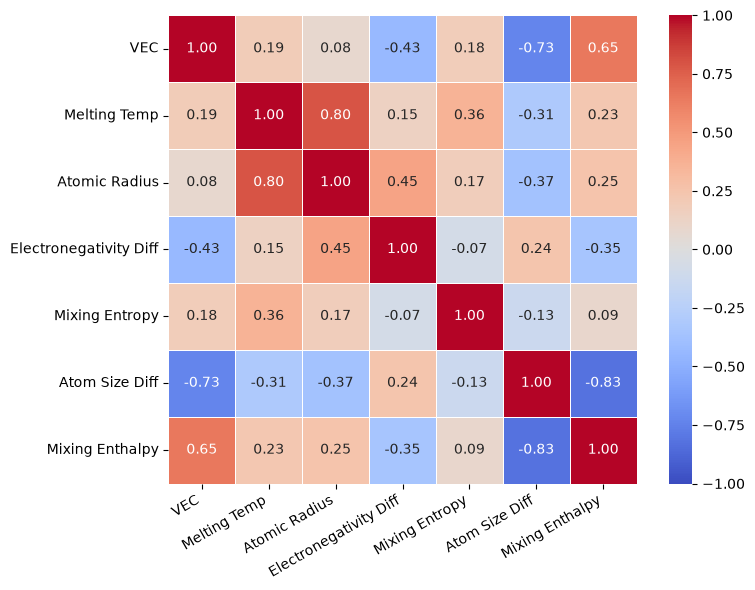

In [115]:
# Correlation plot

plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(), annot=True, fmt='.2f', vmin=-1, vmax=1, square=True, linewidths=0.5, cmap='coolwarm')
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

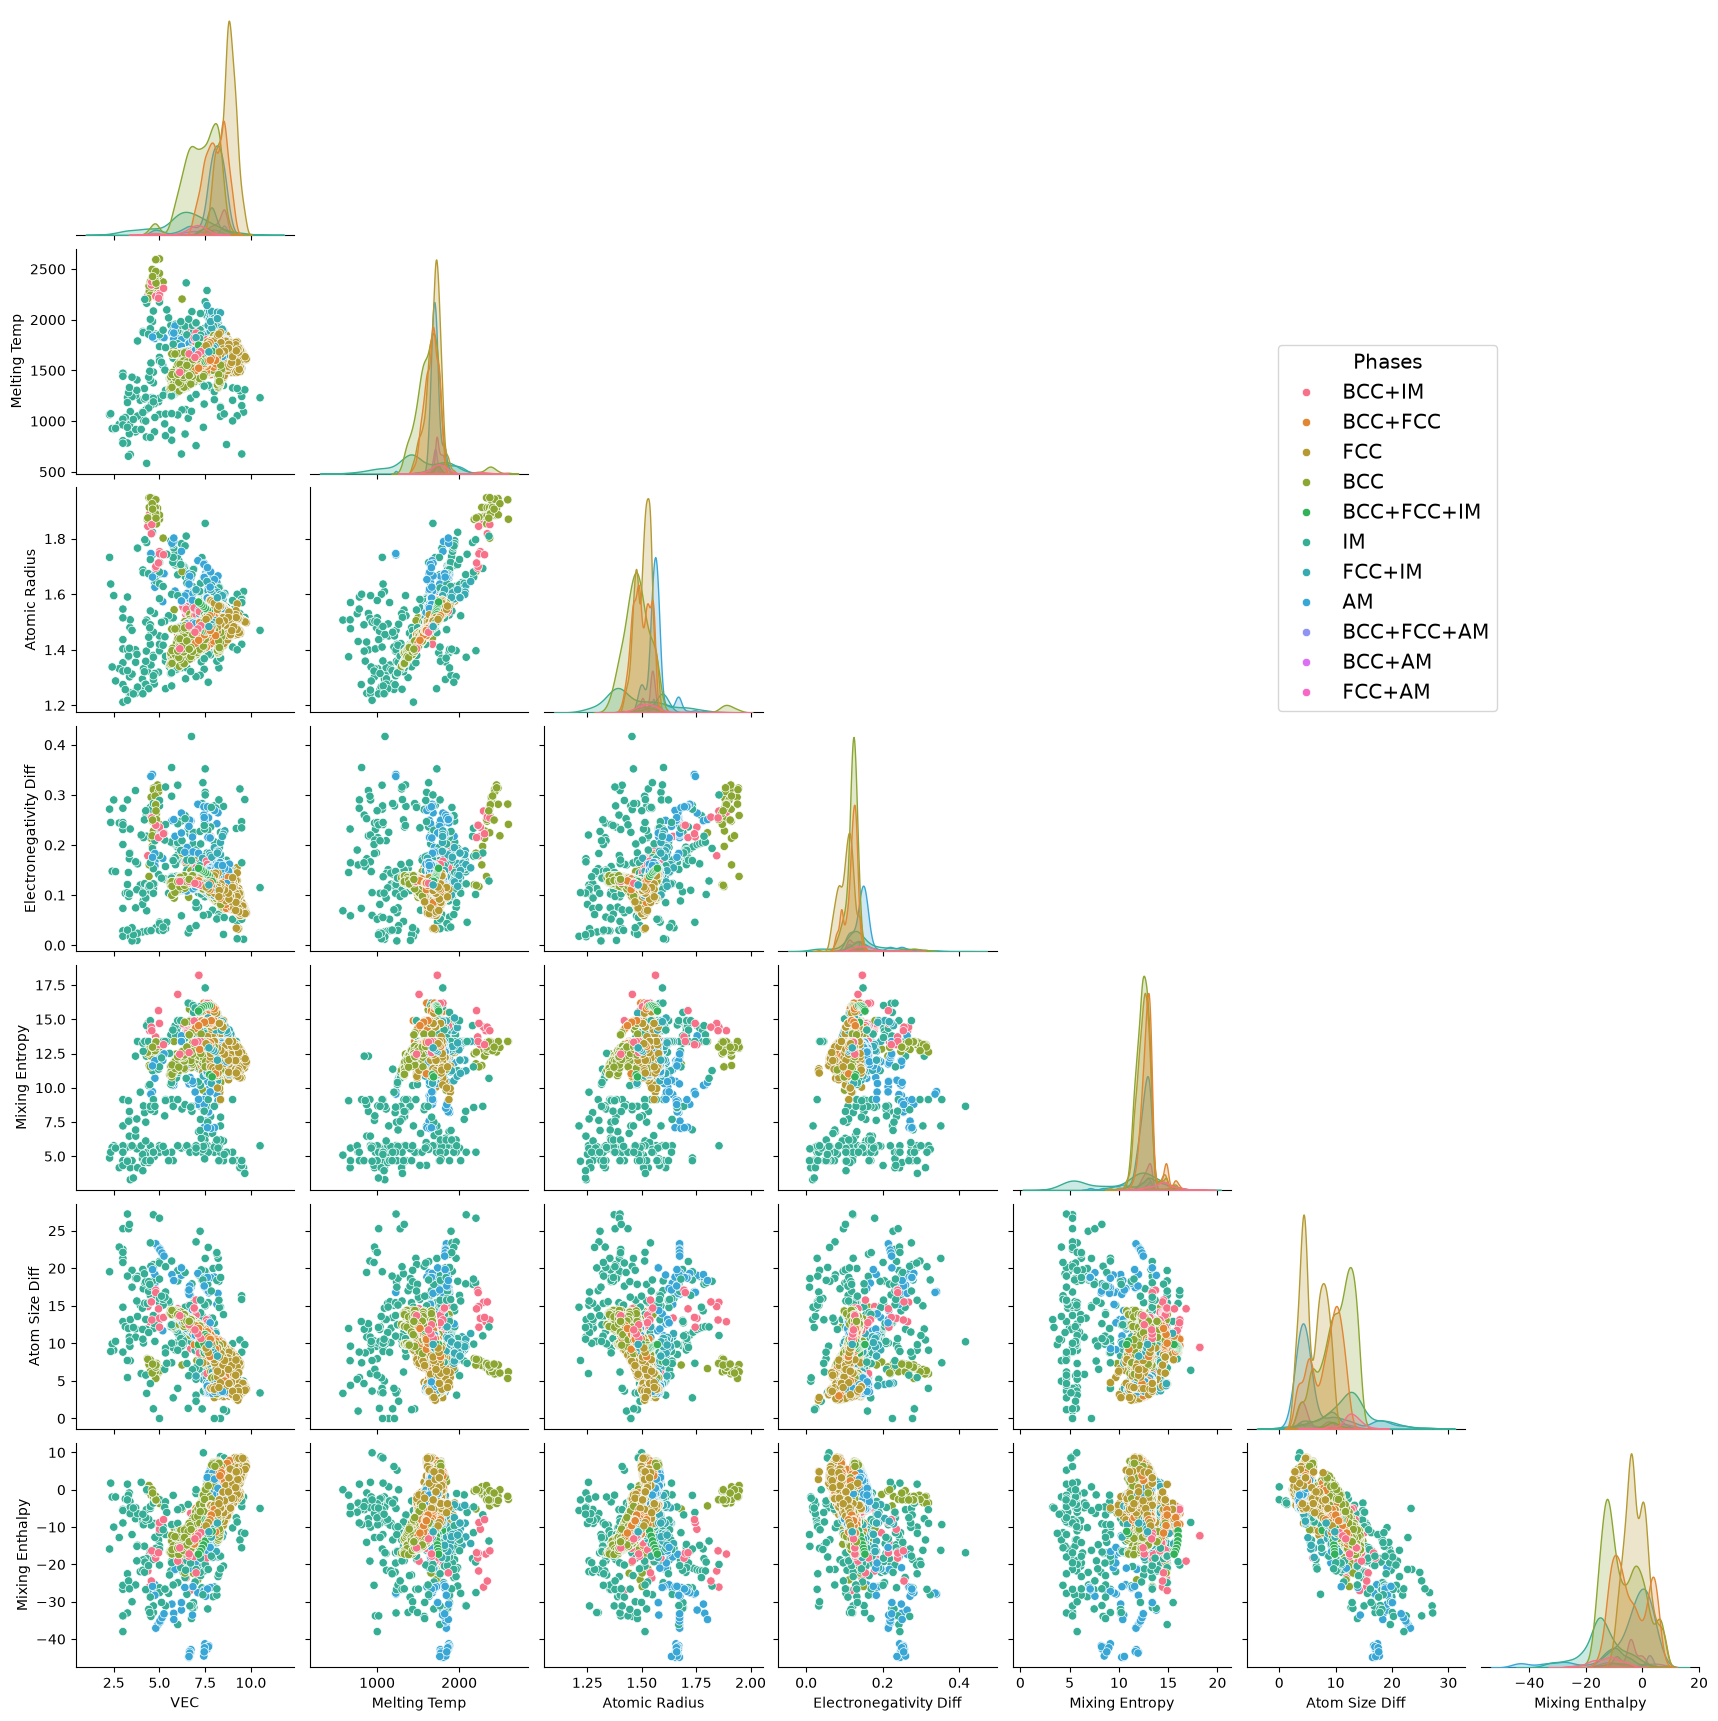

In [116]:
# Combine X and y temporarily
pair_df = X.copy()
pair_df['y_base'] = y_base

# Create pair plot with y as hue
pair_plot = sns.pairplot(pair_df, hue='y_base', diag_kind='kde', corner=True)

# Modify legend
handles, labels = pair_plot._legend_data.values(), pair_plot._legend_data.keys()
if pair_plot._legend is not None: pair_plot._legend.remove()
legend = pair_plot.fig.legend(
    handles=handles, 
    labels=labels,
    title='Phases',
    loc='upper right',
    bbox_to_anchor=(0.8, 0.8),
    fontsize='x-large',
    title_fontsize='x-large',
    frameon=True
)

plt.show()

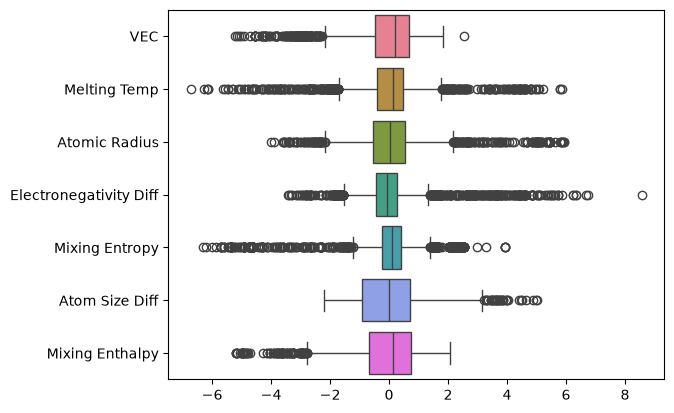

In [117]:
# Box plot
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)
sns.boxplot(data=X_scaled, orient="h")
plt.show()

## Train-Test-Val Split

In [118]:
# Split data to train-test sets
# Later CV will automatically get val set
test_ratio = 0.1

train_idx, test_idx = train_test_split(X.index, test_size=test_ratio, random_state=seed, stratify=y_base)

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_base_train, y_base_test = y_base.loc[train_idx], y_base.loc[test_idx]
y_mulb_train, y_mulb_test = y_mulb.loc[train_idx], y_mulb.loc[test_idx]

print(f"Split  | Train     | Test")
print("-" * 32)
print(f"X      | {str(X_train.shape):<9} | {str(X_test.shape)}")
print(f"y_base | {str(y_base_train.shape):<9} | {str(y_base_test.shape)}")
print(f"y_mulb | {str(y_mulb_train.shape):<9} | {str(y_mulb_test.shape)}")

Split  | Train     | Test
--------------------------------
X      | (5059, 7) | (563, 7)
y_base | (5059,)   | (563,)
y_mulb | (5059, 4) | (563, 4)


# ML Training (Baseline)

In [ ]:
# TODO: Track training and predicting time
# TODO: Train and test curve per epoch, huh?

results = []

In [174]:
# Double points of minority classes, keep majority untouched
# Preserves relative gaps and increases minority representation
minority_double_strategy = {
    'IM': 898,
    'FCC+IM': 278,
    'FCC+AM': 230,
    'BCC+IM': 180,
    'BCC+AM': 114,
    'BCC+FCC+IM': 62,
    'BCC+FCC+AM': 50,
}

smote = SMOTE(
    sampling_strategy=minority_double_strategy,
    random_state=seed,
)

# Create Scale -> SMOTE pipeline
def create_pipe(clf):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('smote', smote),
        ('clf', clf),
    ])

In [175]:
_METRIC_DEFS = {
    "accuracy":           (accuracy_score,  {}),
    "precision_macro":    (precision_score, {"average": "macro",    "zero_division": 0}),
    "recall_macro":       (recall_score,    {"average": "macro",    "zero_division": 0}),
    "f1_macro":           (f1_score,        {"average": "macro",    "zero_division": 0}),
    "precision_weighted": (precision_score, {"average": "weighted", "zero_division": 0}),
    "recall_weighted":    (recall_score,    {"average": "weighted", "zero_division": 0}),
    "f1_weighted":        (f1_score,        {"average": "weighted", "zero_division": 0}),
}

SCORING = {name: make_scorer(f, **kw) for name, (f, kw) in _METRIC_DEFS.items()}

def _metrics(y_true, y_pred):
    return {name: f(y_true, y_pred, **kw) for name, (f, kw) in _METRIC_DEFS.items()}

In [ ]:
def evaluate_model(model, X_train, y_train, X_test, y_test, name="model"):
    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    trm = _metrics(y_train, y_train_pred)
    tem = _metrics(y_test,  y_test_pred)

    print(name)
    print(f"{'Metrics':<18} | {'Train':<6} | {'Test'}")
    print("-" * 37)
    for m in trm:
        print(f"{m:<18} | {trm[m]:<6.4f} | {tem[m]:.4f}")
    print("")

    print(classification_report(y_test, y_test_pred, digits=4, zero_division=0))

    cm = confusion_matrix(y_test, y_test_pred, labels=phase_combs)
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(cm, display_labels=phase_combs).plot(ax=ax, colorbar=False)
    ax.set_title(f"Confusion matrix - {name}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    return {
        "name": name, "train": trm, "test": tem, "cm": cm,
        "y_train_pred": y_train_pred, "y_test_pred": y_test_pred,
    }

In [177]:
def tune_model(pipe, param_distributions, X, y, *,
               n_iter=100, val_size=0.2, random_state=seed,
               scoring=SCORING["f1_macro"], name="model", n_jobs=-1, verbose=1):

    idx = np.arange(len(y))
    tr_idx, val_idx = train_test_split(idx, test_size=val_size, stratify=y, random_state=random_state)
    cv_single_split = [(tr_idx, val_idx)]

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring=scoring,
        cv=cv_single_split,
        refit=True,
        random_state=random_state,
        n_jobs=n_jobs,
        verbose=verbose,
    )
    search.fit(X, y)

    print(f"\n=== RandomizedSearchCV ({name}) ===")
    print(f"Best score: {search.best_score_:.4f}")
    for k, v in search.best_params_.items():
        print(f"  {k}: {v}")

    return search

In [178]:
def compare_default_vs_tuned(base_name, results, metric="f1_macro"):
    by_name = {r["name"]: r for r in results}
    d = by_name[f"{base_name} (default)"]["test"][metric]
    t = by_name[f"{base_name} (tuned)"]["test"][metric]
    winner = "tuned" if t > d else "default"
    delta = t - d
    print(f"{base_name} — test {metric}: default={d:.4f}  tuned={t:.4f}  "
          f"(Δ={delta:+.4f})  →  {winner} wins")
    return winner

## k-Nearest Neighbors

kNN (default)
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.8875 | 0.8366
precision_macro    | 0.7493 | 0.6872
recall_macro       | 0.8324 | 0.7157
f1_macro           | 0.7783 | 0.6869
precision_weighted | 0.9028 | 0.8542
recall_weighted    | 0.8875 | 0.8366
f1_weighted        | 0.8913 | 0.8418

              precision    recall  f1-score   support

          AM     0.8689    0.7361    0.7970        72
         BCC     0.8859    0.8462    0.8656       156
      BCC+AM     0.5000    0.5000    0.5000         6
     BCC+FCC     0.8571    0.9057    0.8807       106
  BCC+FCC+AM     0.6667    1.0000    0.8000         2
  BCC+FCC+IM     0.2000    0.3333    0.2500         3
      BCC+IM     1.0000    0.5556    0.7143         9
         FCC     0.9695    0.9203    0.9442       138
      FCC+AM     0.3500    0.5833    0.4375        12
      FCC+IM     0.6250    0.7143    0.6667        14
          IM     0.6364    0.7778    0.7000        45

   

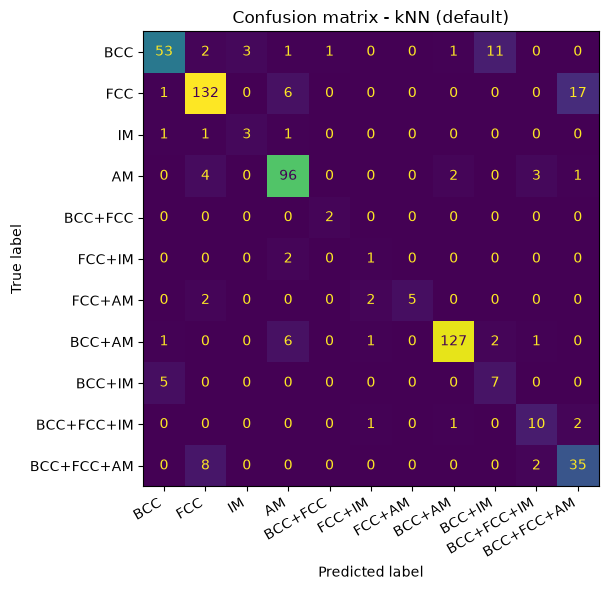

In [179]:
# Evaluate default kNN

knn_default = create_pipe(KNeighborsClassifier())
knn_default.fit(X_train, y_base_train)
result = evaluate_model(knn_default, X_train, y_base_train, X_test, y_base_test, name="kNN (default)")
results.append(result)

In [180]:
# Tune kNN
knn_params = {
    "clf__n_neighbors": randint(3, 16),
    "clf__weights":     ["uniform", "distance"],
    "clf__p":           [1, 2],
    "clf__metric":      ["euclidean", "manhattan", "minkowski"],
}

# Random search
knn_search = tune_model(
    create_pipe(KNeighborsClassifier()), knn_params,
    X_train, y_base_train, n_iter=100, name="kNN",
)
knn_tuned = knn_search.best_estimator_

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (kNN) ===
Best score: 0.6476
  clf__metric: euclidean
  clf__n_neighbors: 11
  clf__p: 2
  clf__weights: uniform


kNN (tuned)
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.8575 | 0.8259
precision_macro    | 0.6929 | 0.6789
recall_macro       | 0.7947 | 0.7436
f1_macro           | 0.7286 | 0.7005
precision_weighted | 0.8760 | 0.8423
recall_weighted    | 0.8575 | 0.8259
f1_weighted        | 0.8624 | 0.8305

              precision    recall  f1-score   support

          AM     0.9123    0.7222    0.8062        72
         BCC     0.8609    0.8333    0.8469       156
      BCC+AM     0.5000    0.6667    0.5714         6
     BCC+FCC     0.8273    0.8585    0.8426       106
  BCC+FCC+AM     0.6667    1.0000    0.8000         2
  BCC+FCC+IM     0.3333    0.3333    0.3333         3
      BCC+IM     0.7500    0.6667    0.7059         9
         FCC     0.9542    0.9058    0.9294       138
      FCC+AM     0.4091    0.7500    0.5294        12
      FCC+IM     0.6000    0.6429    0.6207        14
          IM     0.6545    0.8000    0.7200        45

    a

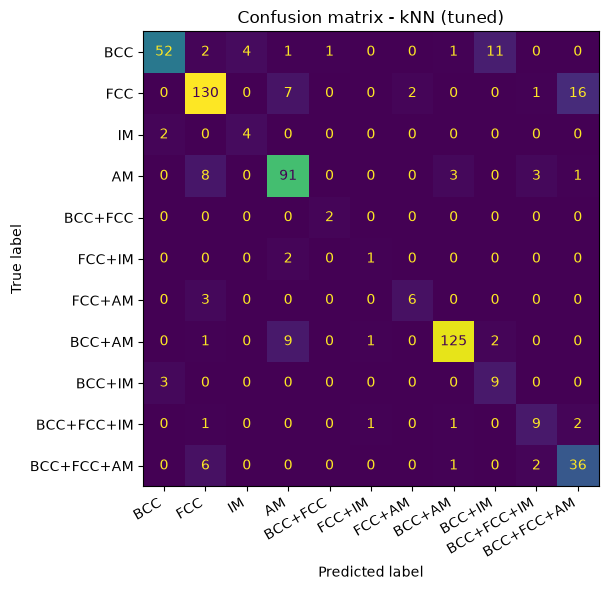

In [181]:
# Evaluate tuned kNN

result = evaluate_model(
    knn_tuned, X_train, y_base_train, X_test, y_base_test,
    name="kNN (tuned)",
)
results.append(result)

In [182]:
compare_default_vs_tuned("kNN", results)

kNN — test f1_macro: default=0.6869  tuned=0.7005  (Δ=+0.0136)  →  tuned wins


'tuned'

## Neural Network

## Support Vector Classifier

## Random Forest

## XGBoost

# ML Training (Multilabel)